# Example of the aitlas toolbox in the context of change detection

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import OMBRIADataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Sentinel-2 imagery and original train/val/test splits

In [ ]:
dataset_config = {
    "data_dir" : "./data/ombria/",
    "imagery": "S2",
    "mode": "train"
}
dataset = OMBRIADataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 624


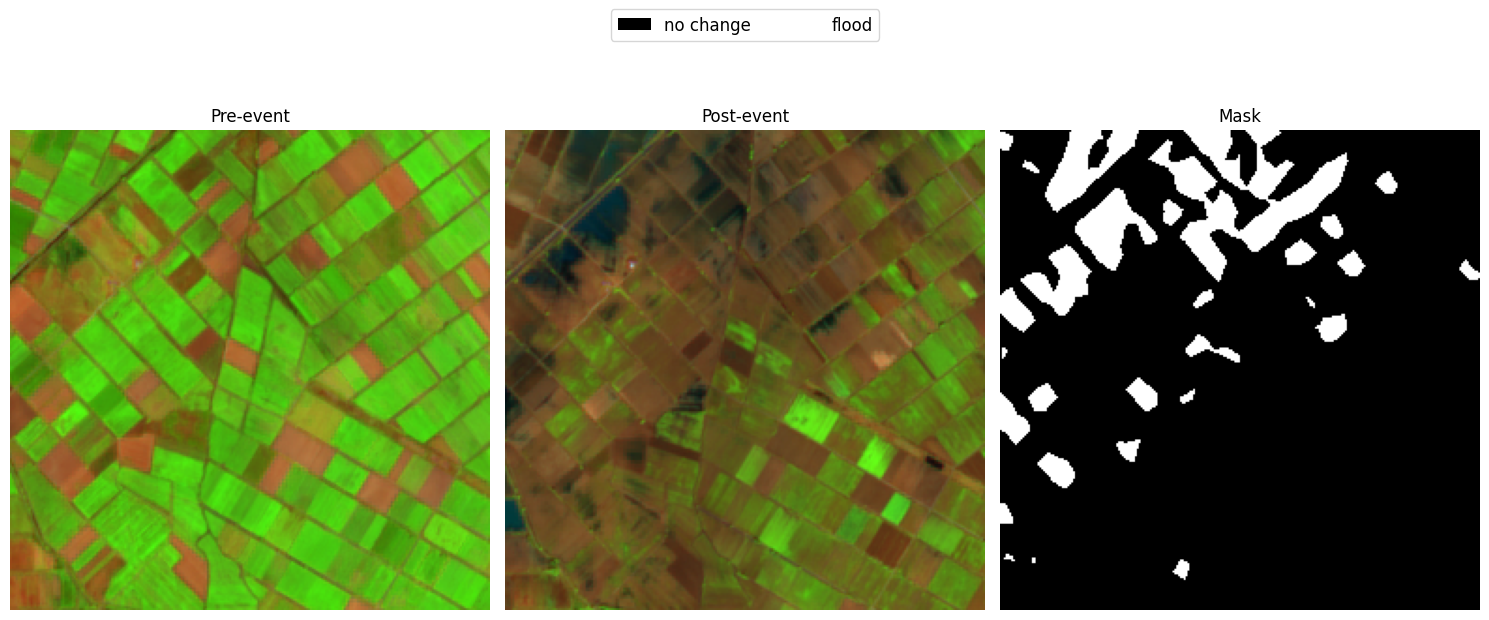

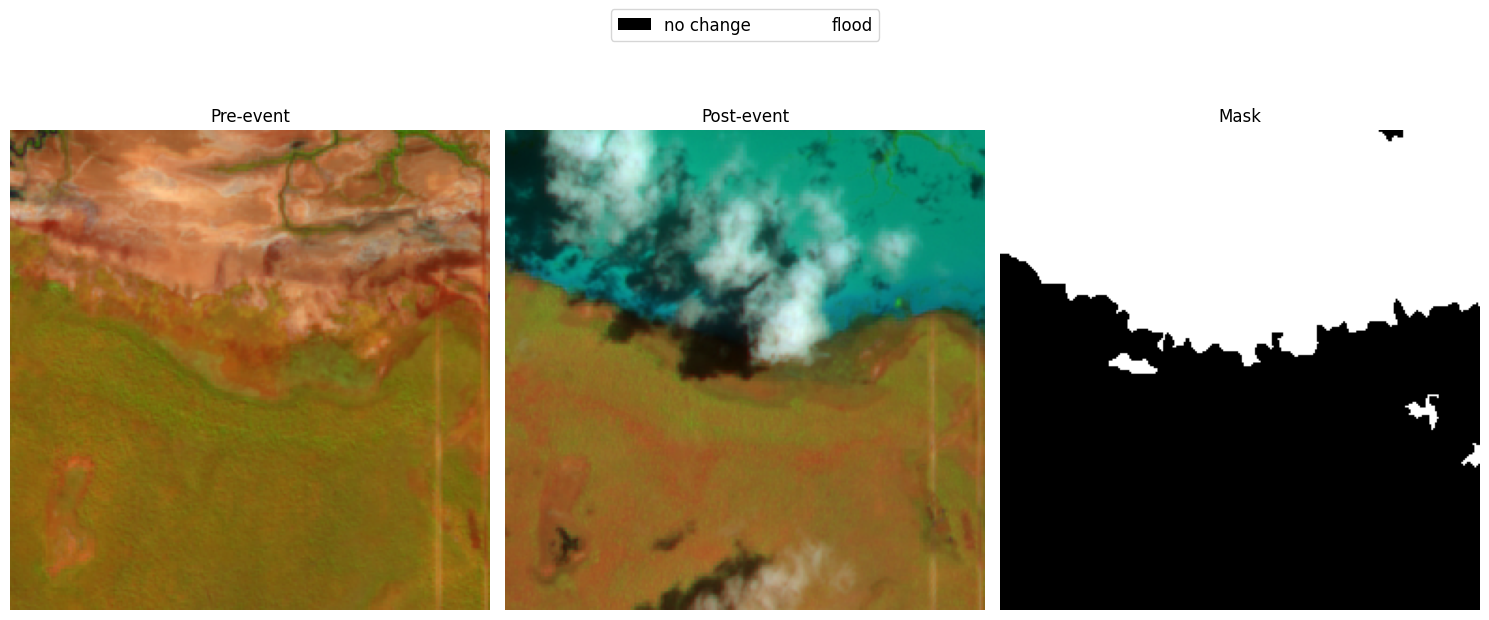

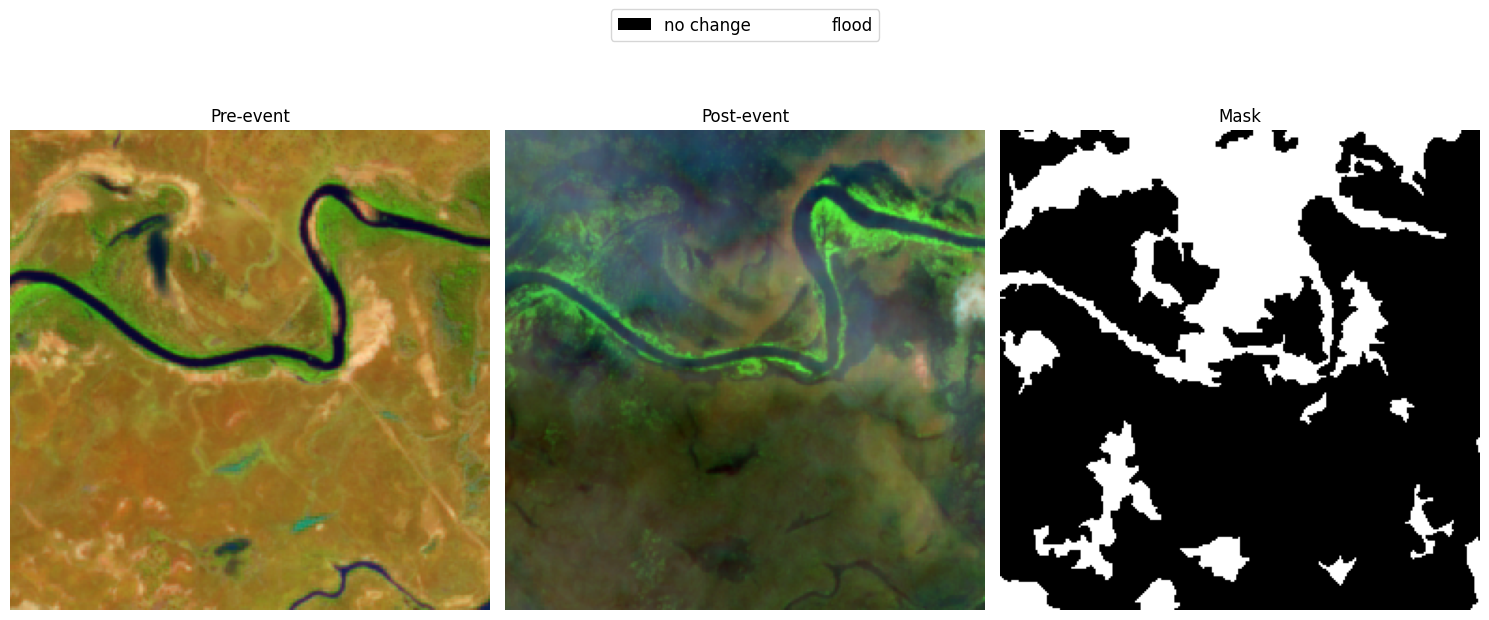

In [8]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(500);

Sentinel-1 & Sentinel-2

In [ ]:
dataset_config = {
    "data_dir" : "./data/ombria/",
    "imagery": "all",
    "selection": "rgb",
    "mode": "train"
}
dataset = OMBRIADataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 624


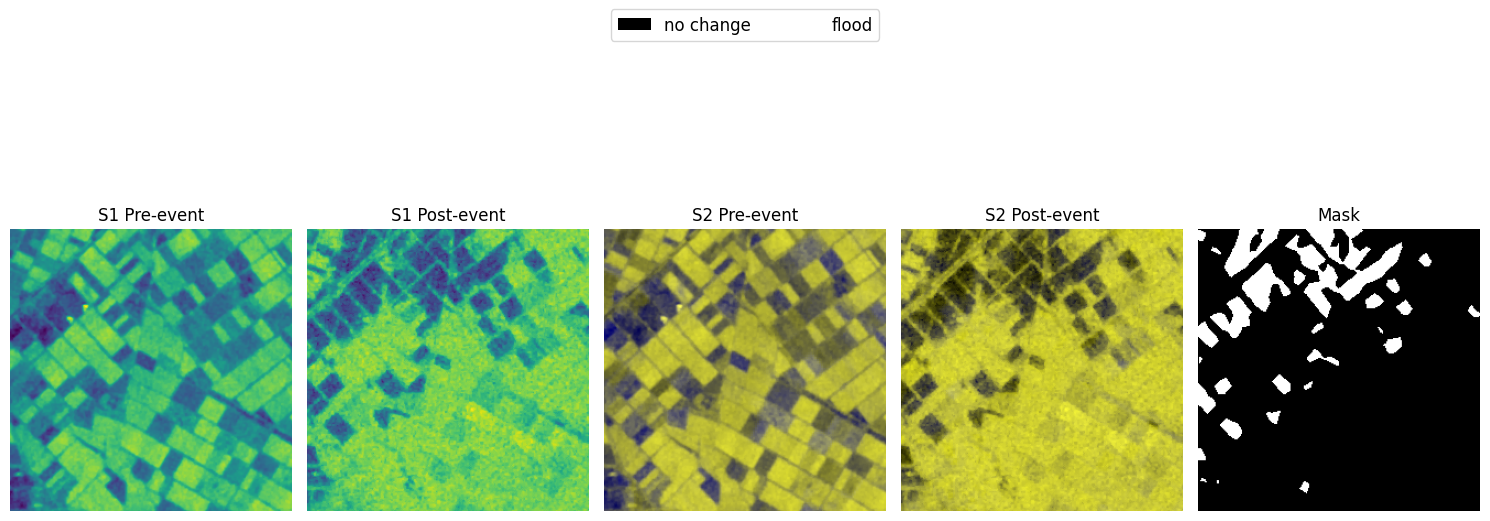

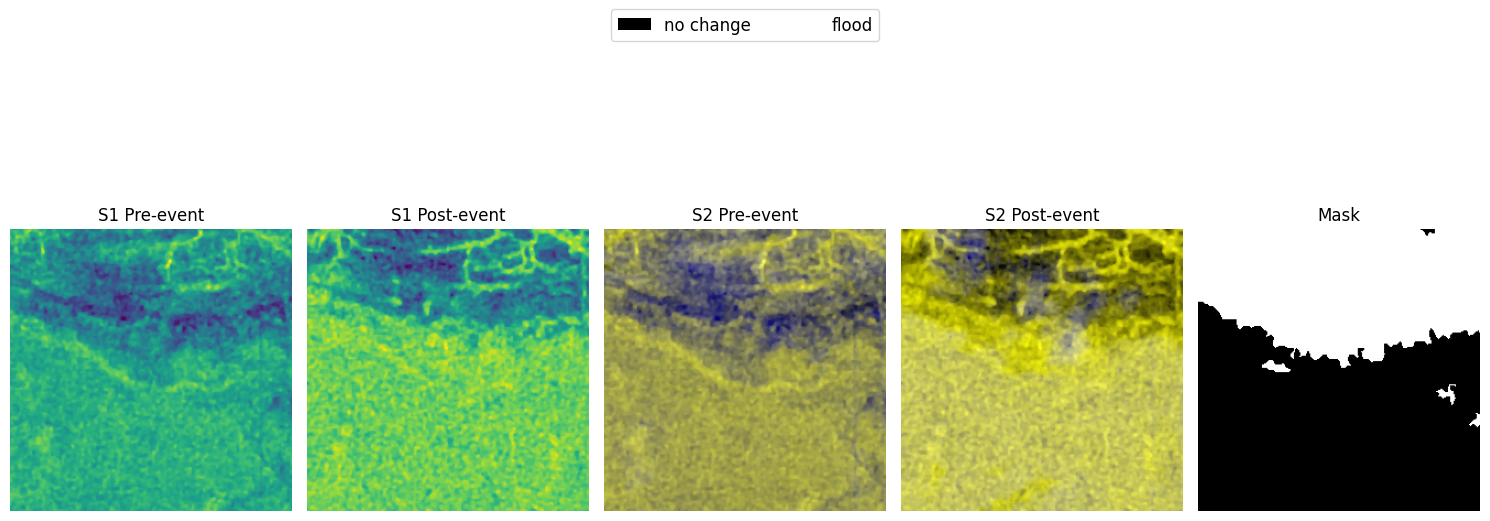

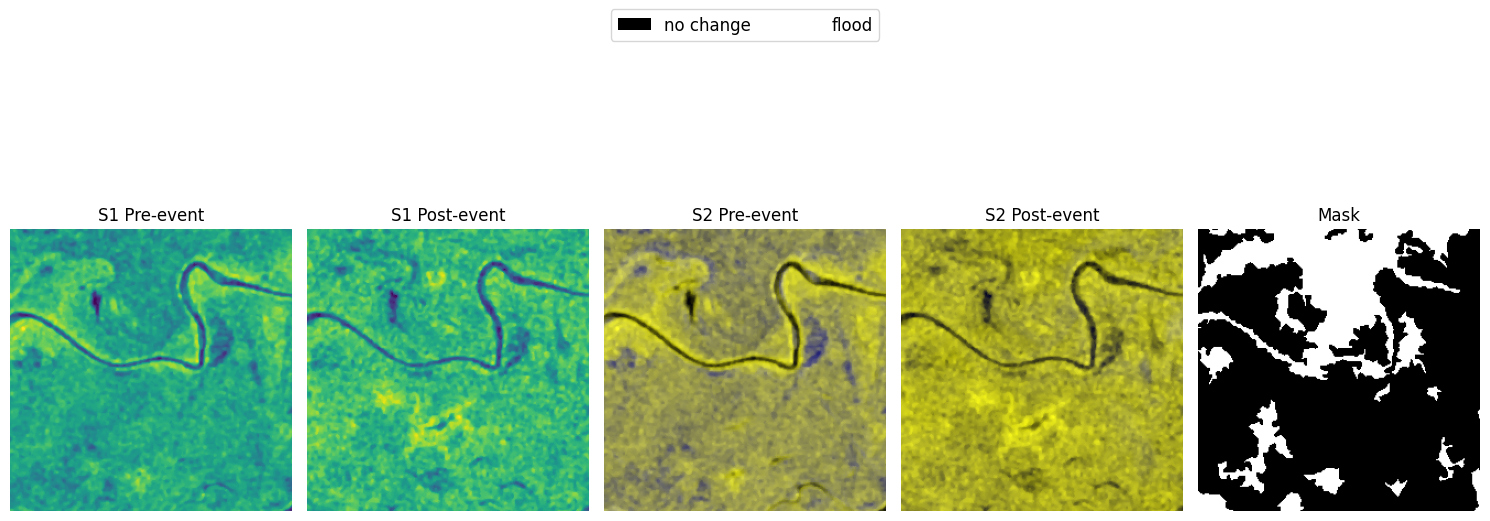

In [20]:
dataset.show_image(100);
dataset.show_image(15);
dataset.show_image(500);

In [81]:
dataset.data_distribution_table()

,Number of pixels
no change,27369004.0
change,13525460.0


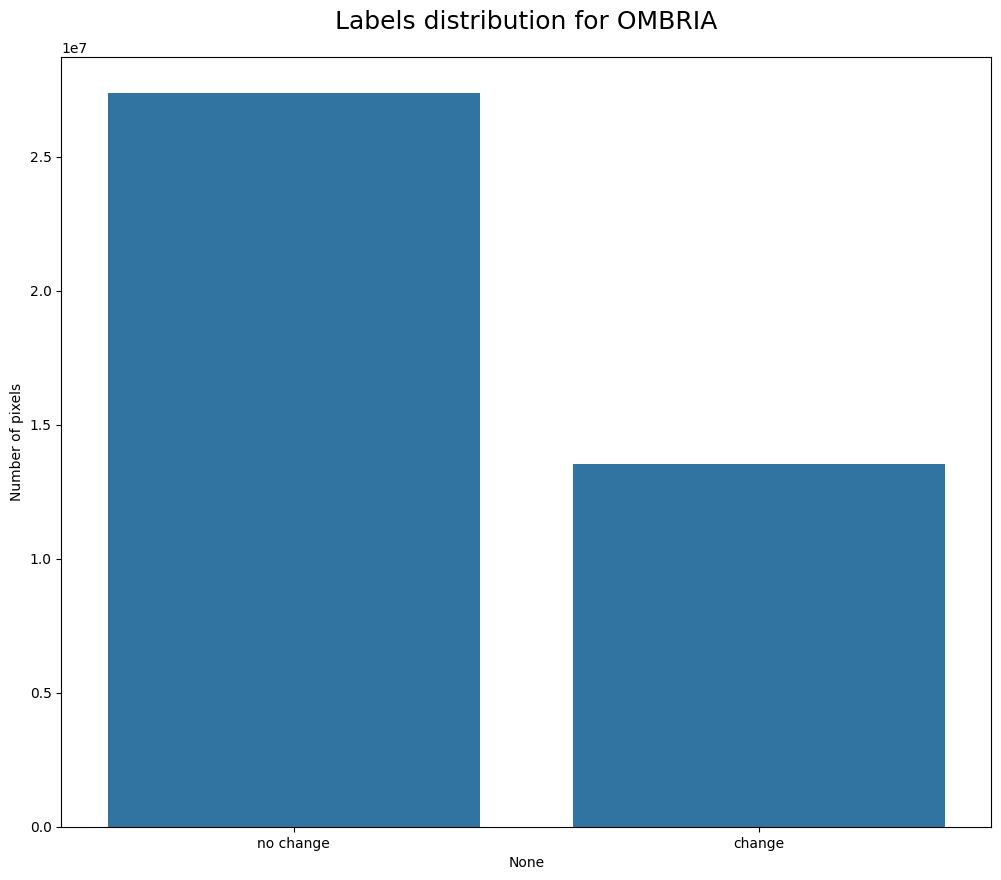

In [82]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/ombria/",
    "csv_file": "./data/ombria/ombria_train.csv", # new 60/20/20 splits
    "imagery": "S2", # can be changed to S1 or all
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = OMBRIADataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/ombria/",
    "csv_file": "./data/ombria/ombria_val.csv",
    "imagery": "S2",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = OMBRIADataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(416, 139)

## Create the model

In [ ]:
epochs = 50
model_directory = "./data/experiments/ombria"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [21]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-01-29 09:05:47,248 INFO Starting training.
training: 100%|██████████| 13/13 [00:19<00:00,  1.52s/it]
2026-01-29 09:06:07,104 INFO epoch: 1, loss:  0.29121
testing on train set: 100%|██████████| 13/13 [00:19<00:00,  1.50s/it]
2026-01-29 09:06:27,841 INFO Accuracy:0.6593402349031888, Accuracy per Class:[0.65869001 0.65999046], Precision Micro:0.6599650985694758, Precision Macro:0.3299825492847379, Precision Weighted:0.4355706672650317, Precision per Class:[0.6599651 0.       ], Recall Micro:0.6573871099031888, Recall Macro:0.49802773854095944, Recall Weighted:0.6573871099031888, Recall per Class:[0.99605548 0.        ], F1_score Micro:0.6586735817425292, F1_score Macro:0.3969527074592425, F1_score Weighted:0.5239699979149172, F1_score per Class:[0.79390541 0.        ], IOU:0.49106136491236696, IOU mean:0.3291223693143557, IOU per Class:[0.65824474 0.        ]
training: 100%|██████████| 13/13 [00:19<00:00,  1.52s/it]
2026-01-29 09:06:47,657 INFO epoch: 2, loss:  0.28103
testing on tr

## Predictions

2026-01-29 11:20:25,591 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/ombria/checkpoint.pth.tar
2026-01-29 11:20:26,021 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/ombria/checkpoint.pth.tar at epoch 51


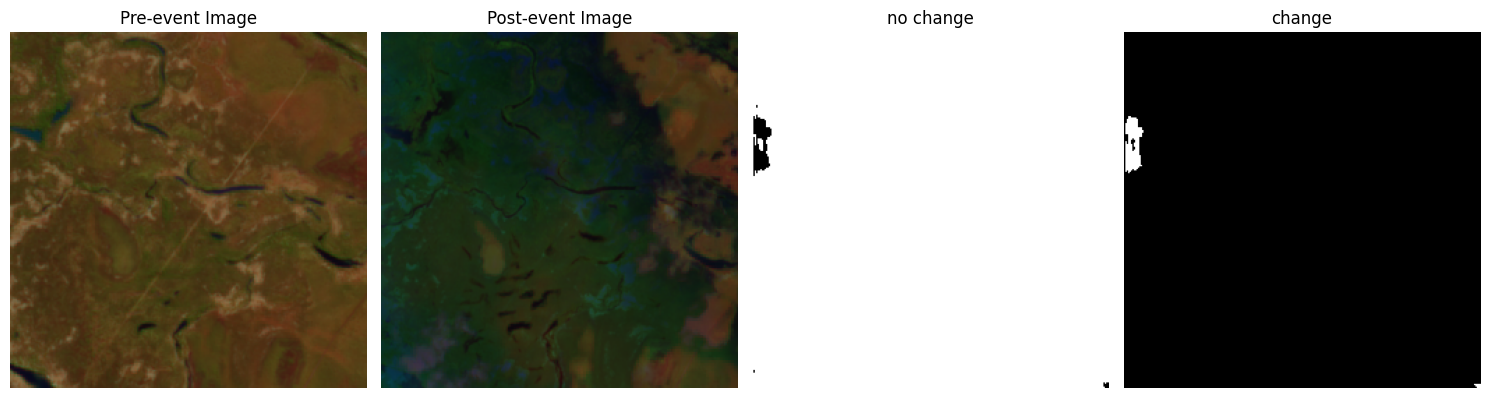

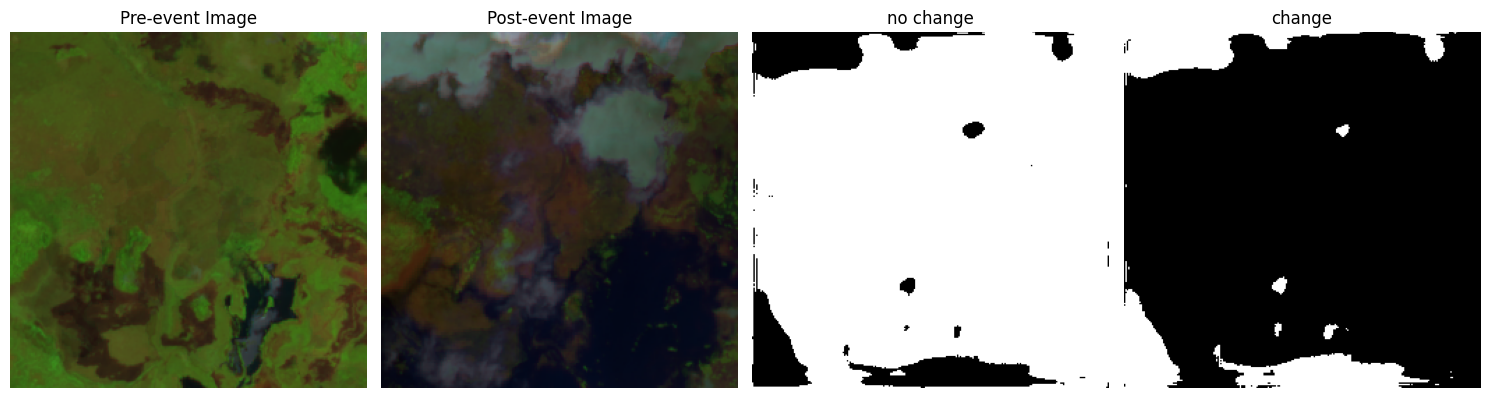

In [ ]:
model_path = "./data/experiments/ombria/checkpoint.pth.tar"
labels = ["no change","change"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/ombria/OmbriaS2/test/BEFORE/S2_before_0695.png")
image2 = image_loader("./data/ombria/OmbriaS2/test/AFTER/S2_after_0695.png")
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/ombria/OmbriaS2/train/BEFORE/S2_before_0205.png")
image2 = image_loader("./data/ombria/OmbriaS2/train/AFTER/S2_after_0205.png")
fig = model.predict_masks(image1, image2, labels, transform)